In [1]:
from arcgis.gis import GIS

In [2]:
gis = GIS(profile="your_online_profile")

In [3]:
layer = gis.content.get("ea4123cc3c42432a93edb88b79f3f3ec").layers[0]
layer

<FeatureLayer url:"https://services7.arcgis.com/JEwYeAy2cc8qOe3o/arcgis/rest/services/tl_2018_37_cousub/FeatureServer/0">

In [4]:
df = layer.query(
   # where = "UseType = 'Residential'",
    where = "FID < 10",
    as_df=True,
   # out_fields="APN, UseType"
)
df.head()

,FID,STATEFP,COUNTYFP,COUSUBFP,COUSUBNS,GEOID,NAME,NAMELSAD,LSAD,CLASSFP,...,NECTAFP,NCTADVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape__Area,Shape__Length,SHAPE
0,1,37,161,90656,01027156,3716190656,Chimney Rock,Chimney Rock township,44,Z1,...,,,N,166283936.0,3295524.0,+35.4494621,-082.1855921,256126365.140625,83317.695625,"{""rings"": [[[-9159430.78506556, 4224257.599087..."
1,2,37,161,90924,01027159,3716190924,Duncans Creek,Duncans Creek township,44,Z1,...,,,N,78056708.0,0.0,+35.4576999,-081.7357455,117907058.582031,49887.653962,"{""rings"": [[[-9104852.82624736, 4222594.682011..."
2,3,37,071,90844,01026697,3707190844,Crowders Mountain,Crowders Mountain township,44,Z1,...,,,N,126685871.0,604597.0,+35.2445623,-081.2918514,191281520.226562,70312.229846,"{""rings"": [[[-9057502.39812054, 4206257.162637..."
3,4,37,071,92692,01026700,3707192692,Riverbend,Riverbend township,44,Z1,...,,,N,145740660.0,5569521.0,+35.3491358,-081.0342585,227951153.476562,78888.006509,"{""rings"": [[[-9030286.66693778, 4205825.958440..."
4,5,37,033,91888,01026518,3703391888,Locust Hill,Locust Hill township,44,Z1,...,,,N,123881118.0,21994.0,+36.4016010,-079.4553569,191633962.734375,61130.41791,"{""rings"": [[[-8852715.77969533, 4349567.137234..."


In [5]:
from arcgis.geometry import Geometry

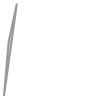

In [6]:
small_geo = Geometry({'rings': [[[-9159430.78506556, 4224257.59908715],
   [-9159427.00020381, 4224301.87053329],
   [-9159420.32103382, 4224332.61469815]]],
 'spatialReference': {'wkid': 102100, 'latestWkid': 3857}})
small_geo

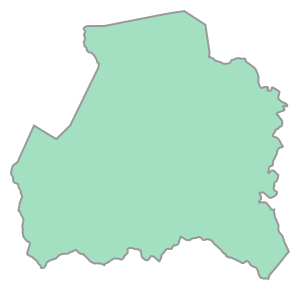

In [7]:
polygon = df["SHAPE"][0]
polygon

In [8]:
out = df["SHAPE"][0].buffer(100000)

In [9]:
out

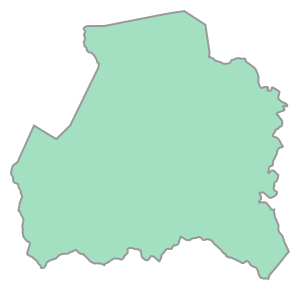

In [10]:
df["SHAPE"][0]

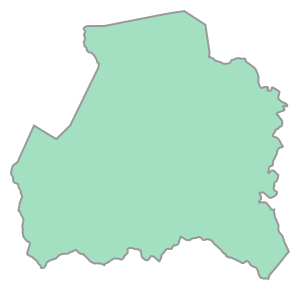

In [11]:
polygon

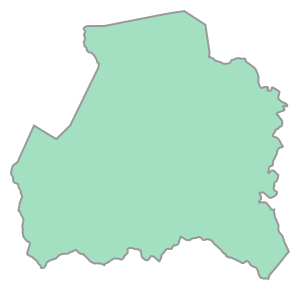

In [12]:
df["SHAPE"][0]

In [13]:
from arcgis_rust import geometry

In [14]:
polygon = geometry(df["SHAPE"][0])
polygon

In [15]:
from arcgis_rust import lazy_polygon

In [16]:
l_poly = lazy_polygon(df["SHAPE"][0])
l_poly

In [17]:
og_poly = df["SHAPE"][0]
simple_poly_dict = og_poly.copy()
simple_poly_dict["rings"] = [og_poly["rings"][0][0:3]]
dict(simple_poly_dict)

{'rings': [[[-9159430.78506556, 4224257.59908715],
   [-9159427.00020381, 4224301.87053329],
   [-9159420.32103382, 4224332.61469815]]],
 'spatialReference': {'wkid': 102100, 'latestWkid': 3857}}

In [18]:
l_poly = lazy_polygon(simple_poly_dict)
l_poly

In [24]:
l_poly.rings = [[[-915943, 4224257.59908715],
   [-9159427.00020381, 4224301.87053329],
   [-9159420.32103382, 4224332.61469815]]]

In [27]:
saved_rings = l_poly.rings
str(saved_rings)

'[[[-915943, 4224257.59908715], [-9159427.00020381, 4224301.87053329], [-9159420.32103382, 4224332.61469815], [4444, 8888]]]'

In [28]:
l_poly.rings[0].push_coord([4444, 8888])

In [29]:
str(l_poly)

'{"spatialReference": {"wkid": 102100, "latestWkid": 3857}, "rings": [[[-915943, 4224257.59908715], [-9159427.00020381, 4224301.87053329], [-9159420.32103382, 4224332.61469815], [4444, 8888], [4444, 8888]]]}'

In [30]:
str(saved_rings)

'[[[-915943, 4224257.59908715], [-9159427.00020381, 4224301.87053329], [-9159420.32103382, 4224332.61469815], [4444, 8888], [4444, 8888]]]'

In [43]:
from arcgis.geometry import Geometry

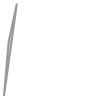

In [44]:
Geometry(str(l_poly))

In [46]:
l_poly.rings[0].push_coord([-9159400, 4224300])

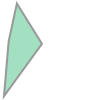

In [47]:
Geometry(str(l_poly))

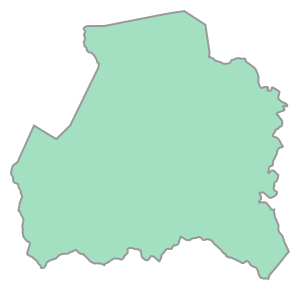

In [23]:
Geometry(str(lazy_polygon))

In [10]:
polygon.rings

In [11]:
#str(polygon.rings)

In [25]:
polyline = geometry({
    'paths': [[[-9159430.78506556, 4224257.59908715], [-9159427.00020381, 4224301.87053329], [-9159420.32103382, 4224332.61469815], [-9159411.30415394, 4224365.68185147], [-9159404.17970624, 4224404.7613425], [-9159397.05525854, 4224443.84097238], [-9159390.71004742, 4224481.00774219], [-9159384.3648363, 4224518.17463761], [-9159374.68003949, 4224555.75158985], [-9159352.19349874, 4224621.06747082], [-9159335.05029436, 4224669.84966845], [-9159306.55249937, 4224735.84945696], [-9159282.61880373, 4224777.9364857], [-9159263.1378881, 4224799.79994115], [-9159230.29862994, 4224828.22249857], [-9159191.33679825, 4224862.79426593], [-9159144.24864112, 4224892.72011342], [-9159094.93409363, 4224925.10571127], [-9159083.57950258, 4224932.89466673], [-9159060.64768142, 4224948.4725942], [-9159042.94787773, 4224960.9076223], [-9159016.78779055, 4224979.90181319], [-9158995.52576229, 4224996.43635132], [-9158981.94478117, 4225012.97091395]]],
    'spatialReference': {'wkid': 102100, 'latestWkid': 3857}
})
polyline

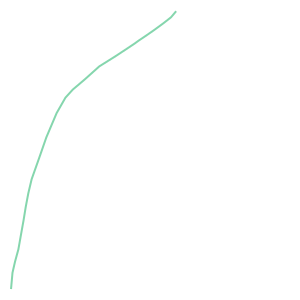

In [26]:
Geometry(str(polyline))

In [27]:
multipoint = geometry({
    'points': [[-9159430.78506556, 4224257.59908715], [-9159427.00020381, 4224301.87053329], [-9159420.32103382, 4224332.61469815], [-9159411.30415394, 4224365.68185147], [-9159404.17970624, 4224404.7613425], [-9159397.05525854, 4224443.84097238], [-9159390.71004742, 4224481.00774219], [-9159384.3648363, 4224518.17463761], [-9159374.68003949, 4224555.75158985], [-9159352.19349874, 4224621.06747082], [-9159335.05029436, 4224669.84966845], [-9159306.55249937, 4224735.84945696], [-9159282.61880373, 4224777.9364857], [-9159263.1378881, 4224799.79994115], [-9159230.29862994, 4224828.22249857], [-9159191.33679825, 4224862.79426593], [-9159144.24864112, 4224892.72011342], [-9159094.93409363, 4224925.10571127], [-9159083.57950258, 4224932.89466673], [-9159060.64768142, 4224948.4725942], [-9159042.94787773, 4224960.9076223], [-9159016.78779055, 4224979.90181319], [-9158995.52576229, 4224996.43635132], [-9158981.94478117, 4225012.97091395]],
    'spatialReference': {'wkid': 102100, 'latestWkid': 3857}
})
multipoint

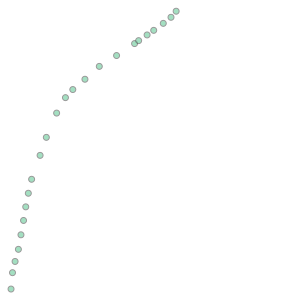

In [28]:
Geometry(str(multipoint))

In [29]:
point = geometry({
    'x': -9159430.78506556,
    'y': 4224257.59908715,
    'spatialReference': {'wkid': 102100, 'latestWkid': 3857},
})
point

In [30]:
str(point)

'{"spatialReference": {"wkid": 102100, "latestWkid": 3857, "vcsWkid": 102100, "latestVcsWkid": 102100}, "x": -9159430.78506556, "y": 4224257.59908715}'

In [ ]:
Geometry(str(point))